# Analysis of Results Common
Comparing individual `_best.csv` files against concatenated batch results, followed by LabelFree Validation.

In [1]:
import pandas as pd
import glob
import os
import numpy as np
import ast
from scipy.stats import pearsonr, zscore
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Ensure pandas is avail


In [2]:


RESULTS_DIR = "../results_val"


## 1. Load Individual `*_best.csv` Files

In [3]:

# Find all protein_best.csv files
best_files = glob.glob(os.path.join(RESULTS_DIR, "*_best.csv"))
print(f"Found {len(best_files)} individual best files.")

dfs = []
for f in best_files:
    try:
        df = pd.read_csv(f)
        dfs.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs:
    df_best_all = pd.concat(dfs, ignore_index=True)
    # Sort for consistency
    df_best_all.sort_values("protein", inplace=True)
    df_best_all.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Best Shape: {df_best_all.shape}")
    display(df_best_all.head())
else:
    df_best_all = pd.DataFrame()
    print("No best files loaded.")


Found 1809 individual best files.
Concatenated Best Shape: (1809, 10)


,protein,best_sample,best_abs_error,mse_all_others,params_dict,feat_coeffs_dict,zscore_genes,zscore_mu,zscore_sigma,zscore_eps
0,A2M,UMUC3_URINARY_TRACT,0.003011,0.836941,"{'alpha': 1.0, 'l1_ratio': 0.1}","{'A1BG': 0.0, 'A2M': 0.05601153568687824, 'AAD...","['A1BG', 'A2M', 'AADAT', 'AASS', 'ABCB6', 'ABI...","[2.821546846143207, 0.8868445119261132, 2.2698...","[2.051967442561821, 1.8051704733585499, 1.2569...",1.000000e-08
1,AARS2,SQ1_LUNG,0.000137,0.140420,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'A2M': 0.0, 'AARS2': 0.15406732440684603, 'AA...","['A2M', 'AARS2', 'AATK', 'ABCC10', 'ABCG1', 'A...","[0.8871246572874287, 3.4942220091470135, 1.098...","[1.8050580488255072, 0.6163178413829652, 1.117...",1.000000e-08
2,AASDHPPT,HEC59_ENDOMETRIUM,0.000364,0.273664,"{'alpha': 0.1, 'l1_ratio': 0.9}","{'A4GALT': -0.0, 'AAAS': 0.0, 'AARS2': 0.0, 'A...","['A4GALT', 'AAAS', 'AARS2', 'AASDHPPT', 'ABCB1...","[2.103931763318877, 5.69152738256317, 3.493995...","[1.5504930921286346, 0.5083307393271205, 0.616...",1.000000e-08
3,ABCB7,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.000245,0.147214,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AASS': -0.0, 'ABCB6': -0.0, 'ABCB7': 0.22758...","['AASS', 'ABCB6', 'ABCB7', 'ABI3', 'ABL1', 'AC...","[2.029682970399025, 4.270079436520009, 4.11333...","[1.4572810773960054, 1.3446260392182268, 0.563...",1.000000e-08
4,ABCD3,CAL33_UPPER_AERODIGESTIVE_TRACT,0.000973,0.202043,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AAAS': -0.0, 'AASDHPPT': -0.0118042086846440...","['AAAS', 'AASDHPPT', 'ABCC3', 'ABCC6', 'ABCD3'...","[5.692029499779636, 4.809574950496353, 3.54140...","[0.5086774092766796, 0.610410849672823, 2.4961...",1.000000e-08


## 2. Load Batch Result Files

In [4]:

# Find batch files (assuming pattern results_batch_*.csv)
batch_files = glob.glob(os.path.join(RESULTS_DIR, "*batch*.csv"))
print(f"Found {len(batch_files)} batch files.")

dfs_batch = []
for f in batch_files:
    try:
        df = pd.read_csv(f)
        dfs_batch.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs_batch:
    df_batch_concat = pd.concat(dfs_batch, ignore_index=True)
    df_batch_concat.sort_values("protein", inplace=True)
    df_batch_concat.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Batch Shape: {df_batch_concat.shape}")
    display(df_batch_concat.head())
else:
    df_batch_concat = pd.DataFrame()
    print("No batch files loaded.")


Found 0 batch files.
No batch files loaded.


## 3. Compare

In [5]:

# Check if they are the same
if not df_best_all.empty and not df_batch_concat.empty:
    # 1. Compare protein lists
    prots_best = set(df_best_all['protein'].unique())
    prots_batch = set(df_batch_concat['protein'].unique())
    
    missing_in_batch = prots_best - prots_batch
    missing_in_best = prots_batch - prots_best
    
    print(f"Proteins in Best: {len(prots_best)}")
    print(f"Proteins in Batch: {len(prots_batch)}")
    
    if missing_in_batch:
        print(f"Proteins in Best but NOT in Batch: {len(missing_in_batch)}")
    if missing_in_best:
        print(f"Proteins in Batch but NOT in Best: {len(missing_in_best)}")
        
    # Check shape equality
    if df_best_all.shape == df_batch_concat.shape:
         try:
            pd.testing.assert_frame_equal(df_best_all, df_batch_concat, check_like=True)
            print("SUCCESS: DataFrames are identical (pd.testing.assert_frame_equal passed).")
         except AssertionError as e:
            print(f"DataFrames are NOT identical: {e}")
    else:
        print("Shapes differ, cannot be identical.")

else:
    print("Cannot compare - one or both dataframes are empty.")


Cannot compare - one or both dataframes are empty.


## 4. LabelFree Data Loading (Pre-Processed with Gene Symbols)

In [6]:


# --- UPDATED: Load from Validation Folder ---
RNA_PATH = "../val_data/LabelFree_transcriptomics.joblib"
PROT_PATH = "../val_data/LabelFree_proteomics.joblib"

print(f"Loading Validation LabelFree Data from: {RNA_PATH} and {PROT_PATH}")

rna_df = None
prot_df = None

if os.path.exists(RNA_PATH) and os.path.exists(PROT_PATH):
    try:
        rna_df = joblib.load(RNA_PATH)
        prot_df = joblib.load(PROT_PATH)
        
        # Ensure we have pandas DataFrames
        if not isinstance(rna_df, pd.DataFrame):
            print("Warning: Loaded RNA object is not a DataFrame.")
        if not isinstance(prot_df, pd.DataFrame):
            print("Warning: Loaded Protein object is not a DataFrame.")

        print(f"LabelFree RNA Shape: {rna_df.shape}")
        print(f"LabelFree Protein Shape: {prot_df.shape}")
        
        # Display heads if possible (requires IPython display which is avail in notebook)
        try:
            display(rna_df.head())
            display(prot_df.head())
        except:
            print(rna_df.head())
            print(prot_df.head())
        
    except Exception as e:
        print(f"Error loading joblib files: {e}")
else:
    print(f"Validation files not found. Current CWD: {os.getcwd()}")
    if not os.path.exists("../validation"):
        print("Folder ../validation does not exist.")


Loading Validation LabelFree Data from: ../val_data/LabelFree_transcriptomics.joblib and ../val_data/LabelFree_proteomics.joblib
LabelFree RNA Shape: (360, 11822)
LabelFree Protein Shape: (360, 2156)


,A1BG,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMP,AARS2,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_1,0.514111,6.201943,-0.386887,-1.503843,-0.966503,-0.240688,1.826314,-1.362016,1.256755,-2.144431,...,-2.035116,-0.682085,-1.205945,-1.748844,-0.482229,-2.949726,0.976757,0.883982,-3.000260,-1.856075
BRAIN_2,0.514111,6.201943,-0.386887,1.859582,-2.530458,-1.819644,1.826314,-0.713800,1.256755,-1.056881,...,-0.669108,-0.935492,-1.205945,-1.402036,-0.429228,-2.632568,0.976757,0.883982,-1.795645,-1.856075
BRAIN_3,0.514111,6.201943,-0.386887,-2.767110,-0.661573,-0.757123,1.826314,-1.588796,1.256755,-2.910776,...,-2.484710,-1.084626,-1.205945,-2.369533,-3.021866,-2.949726,0.976757,0.639033,-3.000260,-1.856075
BRAIN_4,-0.608501,6.201943,-0.386887,-1.896112,-0.574620,-1.129005,1.826314,1.905519,1.256755,-2.433374,...,-0.833488,-1.084626,-0.542325,-1.978968,0.040420,-2.949726,0.976757,0.883982,-2.201815,-1.856075
BRAIN_5,0.464969,6.201943,-0.386887,-0.590459,-2.102846,-0.272810,1.826314,-1.448003,1.256755,-2.477518,...,-1.204298,-1.084626,-1.205945,-1.693743,-1.265468,-2.949726,0.976757,-1.025074,-3.000260,-1.856075


,A2M,AARS2,AASDHPPT,ABCB7,ABCD3,ABCE1,ABCF1,ABHD10,ABHD11,ABHD12,...,YWHAH,YWHAQ,YWHAZ,ZC3H15,ZC3HAV1,ZFR,ZMPSTE24,ZNF207,ZW10,ZYX
BRAIN_1,-0.541968,-0.483809,0.590807,-0.575177,0.025607,0.422055,-0.293402,0.659387,-0.399078,0.362477,...,0.088476,-0.521241,-0.616460,-0.418707,1.813095,-0.343355,-0.265732,-0.580579,0.726533,-0.635437
BRAIN_2,-0.421435,-0.225612,0.402964,0.166472,0.487337,0.045931,0.240724,0.586244,-0.395021,1.171643,...,-0.178545,-0.512026,-0.865005,-0.537153,1.813095,0.790495,-0.659573,0.847050,0.712355,-0.357079
BRAIN_3,-0.363243,-0.286192,0.621886,0.155601,0.404772,0.461451,0.889711,0.349710,-0.304507,1.209467,...,-0.027525,-0.600047,-0.657375,0.161978,1.813095,-0.417112,-0.372266,-0.643849,1.157941,-0.605588
BRAIN_4,-0.456482,-0.302890,0.577518,0.072639,0.503178,-0.139267,0.513540,0.643259,0.579167,1.730900,...,-0.174050,-0.637555,-0.705958,-0.468506,1.813095,-0.405290,-0.256839,-0.633710,1.095334,-0.545768
BRAIN_5,-0.423357,-0.144344,1.152524,0.291115,0.325413,-0.050471,0.592203,0.733507,-0.065745,1.204582,...,-0.213983,-0.635907,-0.635075,0.197522,1.813095,-0.359887,-0.188396,0.107446,1.390910,-0.648760


## 5. Check Features & Normalize

In [7]:

if rna_df is not None:
    # 1. SKIP Normalization (Data already normalized) - Just handle NaNs
    print("Skipping z-score normalization (data already normalized). Filling NaNs with 0...")
    
    # Just fill NaNs (crucial to prevent NaNs in prediction)
    rna_z = rna_df.fillna(0)
    
    print("NaNs filled with 0.")
    display(rna_z.head())
    
    # Check coverage
    if not df_best_all.empty:
        import ast
        example_coeffs = ast.literal_eval(df_best_all.iloc[0]['feat_coeffs_dict'])
        needed = list(example_coeffs.keys())
        present = [g for g in needed if g in rna_z.columns]
        print(f"Example Model ({df_best_all.iloc[0]['protein']}) feature coverage: {len(present)}/{len(needed)}")


Skipping z-score normalization (data already normalized). Filling NaNs with 0...
NaNs filled with 0.


,A1BG,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMP,AARS2,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_1,0.514111,6.201943,-0.386887,-1.503843,-0.966503,-0.240688,1.826314,-1.362016,1.256755,-2.144431,...,-2.035116,-0.682085,-1.205945,-1.748844,-0.482229,-2.949726,0.976757,0.883982,-3.000260,-1.856075
BRAIN_2,0.514111,6.201943,-0.386887,1.859582,-2.530458,-1.819644,1.826314,-0.713800,1.256755,-1.056881,...,-0.669108,-0.935492,-1.205945,-1.402036,-0.429228,-2.632568,0.976757,0.883982,-1.795645,-1.856075
BRAIN_3,0.514111,6.201943,-0.386887,-2.767110,-0.661573,-0.757123,1.826314,-1.588796,1.256755,-2.910776,...,-2.484710,-1.084626,-1.205945,-2.369533,-3.021866,-2.949726,0.976757,0.639033,-3.000260,-1.856075
BRAIN_4,-0.608501,6.201943,-0.386887,-1.896112,-0.574620,-1.129005,1.826314,1.905519,1.256755,-2.433374,...,-0.833488,-1.084626,-0.542325,-1.978968,0.040420,-2.949726,0.976757,0.883982,-2.201815,-1.856075
BRAIN_5,0.464969,6.201943,-0.386887,-0.590459,-2.102846,-0.272810,1.826314,-1.448003,1.256755,-2.477518,...,-1.204298,-1.084626,-1.205945,-1.693743,-1.265468,-2.949726,0.976757,-1.025074,-3.000260,-1.856075


Example Model (A2M) feature coverage: 1193/1194


In [8]:

# 5.5 Setting up Analysis
print("\n=======================================================")
print(" PART 1: Analysis with ALL Tissues (No Filtering) ")
print("=======================================================\n")

# Note: Filtering will be done in Part 2 below.



 PART 1: Analysis with ALL Tissues (No Filtering) 



In [9]:

# --- CHECK PERCENTAGE OF ZEROS PER TISSUE ---
if 'rna_z' in locals() and not rna_z.empty:
    print("\n--- Percentage of Zeros per Tissue (RNA Data) ---")
    
    # Helper to get tissue from index (if not already defined)
    def get_tissue_check(idx):
        parts = idx.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return idx
    
    rna_zeros = rna_z.copy()
    rna_zeros['Tissue'] = [get_tissue_check(x) for x in rna_zeros.index]
    
    # Calculate % zeros: (Count of 0s / Total Cells) * 100
    zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)
    
    display(zero_stats.sort_values(ascending=False).to_frame(name="% Zeros"))
else:
    print("rna_z not found. Cannot check zeros.")
# --------------------------------------------



--- Percentage of Zeros per Tissue (RNA Data) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_24060\1257190750.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)


,% Zeros
Tissue,
BRAIN,0.0
COLON,0.0
LIVER,0.0
LUNG,0.0
PROSTATE,0.0


## 6. Predict LabelFree Proteins & Evaluate

In [10]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total LabelFree RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total LabelFree RNA Features: 11822
Protein A2M: Needed 1194, Present 1193, Missing 1
  -> First 3 missing: ['ZIM2']
Protein AARS2: Needed 1194, Present 1189, Missing 5
  -> First 3 missing: ['FOLR2', 'C1QTNF7', 'RSPH9']
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1185, Missing 9
  -> First 3 missing: ['TLR8', 'C1QC', 'CD209']
Protein ABCD3: Needed 1194, Present 1192, Missing 2
  -> First 3 missing: ['SLC9B1', 'FOLR2']


In [11]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 186 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,AASDHPPT,1.726903,-0.524984,-0.523790,True
1,ABHD11,3.987706,-0.259348,-0.263247,True
2,ACIN1,0.982995,0.541138,0.533513,True
3,ACSF2,0.332065,0.640333,0.640814,True
4,ACSL1,0.513366,0.654596,0.655643,True


Average MSE: 2.4257962161211837
Average Correlation: 0.05245146647657997
Average Cosine Similarity: 0.0584329941383924

Error Table (Predicted - Actual):


,BRAIN_1,BRAIN_2,BRAIN_3,BRAIN_4,BRAIN_5,BRAIN_6,BRAIN_7,BRAIN_8,BRAIN_9,BRAIN_10,...,PROSTATE_56,PROSTATE_57,PROSTATE_58,PROSTATE_59,PROSTATE_60,PROSTATE_61,PROSTATE_62,PROSTATE_63,PROSTATE_64,PROSTATE_65
AASDHPPT,-0.019403,0.179028,-0.009524,-0.114802,-0.563698,0.385456,-0.207484,0.068384,-0.402506,-0.131336,...,1.940491,1.730154,1.629894,2.095597,1.646635,1.851816,1.877779,1.707360,1.886623,1.689847
ABHD11,1.736332,0.934154,1.893455,0.871993,0.739616,0.196883,0.610987,0.191084,0.612905,0.085125,...,-3.184725,-4.263260,-4.281833,-4.478165,-4.617350,-3.828038,-4.182316,-3.463784,-4.613087,-3.445549
ACIN1,0.252292,-1.082091,-0.632084,0.285257,-0.509334,0.484253,-0.128327,-0.980345,0.497003,0.471933,...,-1.045911,-0.427771,-1.065740,-1.234303,-0.746972,-1.329632,-1.267527,-0.928277,-0.772007,-0.302435
ACSF2,0.533793,1.424817,0.017089,-0.084064,0.169709,-0.477149,-0.451511,-0.125645,-0.736845,-0.450065,...,-0.172101,-0.040156,0.037149,-0.170556,-0.003963,-0.066344,-0.048734,-0.047503,-0.022732,-0.009568
ACSL1,0.031345,-0.053355,-0.422554,0.443874,0.936384,1.360622,0.636627,0.532759,0.061888,0.553773,...,-0.153814,-0.240270,-0.548307,-0.386164,-0.601463,0.046886,-0.203457,-0.226091,-0.436957,-0.020759


In [12]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
7,AGR2,5.808203,0.817166,0.840875
91,KLC1,0.342910,0.808166,0.806793
99,MAP1B,1.093228,0.768220,0.759369
116,PEBP1,0.166104,0.750817,0.751474
32,COL12A1,0.391085,0.748741,0.760669
20,CAMK2G,0.281744,0.745476,0.745495
31,CNP,0.692615,0.739072,0.731076
176,TXNRD1,0.326939,0.719612,0.720677
40,COPS6,1.506959,0.698004,0.693624
8,AHSA1,0.483857,0.664151,0.662516



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
116,PEBP1,0.166104,0.750817,0.751474
22,CAV1,0.229748,0.624307,0.597219
122,PPA2,0.278336,0.516782,0.510099
20,CAMK2G,0.281744,0.745476,0.745495
176,TXNRD1,0.326939,0.719612,0.720677
3,ACSF2,0.332065,0.640333,0.640814
91,KLC1,0.342910,0.808166,0.806793
24,CDH1,0.346689,0.537006,0.636738
32,COL12A1,0.391085,0.748741,0.760669
125,PRDX3,0.397137,0.177446,0.176696



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
7,AGR2,5.808203,0.817166,0.840875
91,KLC1,0.342910,0.808166,0.806793
32,COL12A1,0.391085,0.748741,0.760669
99,MAP1B,1.093228,0.768220,0.759369
116,PEBP1,0.166104,0.750817,0.751474
20,CAMK2G,0.281744,0.745476,0.745495
31,CNP,0.692615,0.739072,0.731076
176,TXNRD1,0.326939,0.719612,0.720677
40,COPS6,1.506959,0.698004,0.693624
72,GLIPR2,1.816613,0.662106,0.663175



Total NaNs in Error Table: 0


In [13]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
LUNG        1.585851
BRAIN       1.638199
COLON       1.919945
LIVER       2.274703
PROSTATE    5.081583
Name: MSE, dtype: float64

In [14]:

# =======================================================
# PART 2: Analysis with FILTERED Tissues
# =======================================================

excluded_tissues = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']

if 'rna_z' in locals() and 'prot_df' in locals():
    def get_tissue_filter(sample_name):
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name

    print(f"Original Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Identify samples to remove
    samples_to_remove = []
    for s in rna_z.index:
        t = get_tissue_filter(s)
        if t in excluded_tissues:
            samples_to_remove.append(s)

    print(f"Removing {len(samples_to_remove)} samples from excluded tissues: {excluded_tissues}")

    # Filter in-place (or overwrite variable)
    # We overwrite rna_z and prot_df so the duplicated cells works as is
    rna_z = rna_z.drop(index=samples_to_remove, errors='ignore')
    prot_df = prot_df.drop(index=samples_to_remove, errors='ignore')

    print(f"Filtered Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Print remaining tissues
    remaining_tissues = sorted(list(set([get_tissue_filter(s) for s in rna_z.index])))
    print(f"\nRemaining Tissues ({len(remaining_tissues)}): {remaining_tissues}")
else:
    print("Dataframes rna_z or prot_df not found.")


Original Samples: RNA=360, Prot=360
Removing 0 samples from excluded tissues: ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
Filtered Samples: RNA=360, Prot=360

Remaining Tissues (5): ['BRAIN', 'COLON', 'LIVER', 'LUNG', 'PROSTATE']


## 6. Predict LabelFree Proteins & Evaluate

In [15]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total LabelFree RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total LabelFree RNA Features: 11822
Protein A2M: Needed 1194, Present 1193, Missing 1
  -> First 3 missing: ['ZIM2']


Protein AARS2: Needed 1194, Present 1189, Missing 5
  -> First 3 missing: ['FOLR2', 'C1QTNF7', 'RSPH9']
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1185, Missing 9
  -> First 3 missing: ['TLR8', 'C1QC', 'CD209']
Protein ABCD3: Needed 1194, Present 1192, Missing 2
  -> First 3 missing: ['SLC9B1', 'FOLR2']


In [16]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 186 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,AASDHPPT,1.726903,-0.524984,-0.523790,True
1,ABHD11,3.987706,-0.259348,-0.263247,True
2,ACIN1,0.982995,0.541138,0.533513,True
3,ACSF2,0.332065,0.640333,0.640814,True
4,ACSL1,0.513366,0.654596,0.655643,True


Average MSE: 2.4257962161211837
Average Correlation: 0.05245146647657997
Average Cosine Similarity: 0.0584329941383924

Error Table (Predicted - Actual):


,BRAIN_1,BRAIN_2,BRAIN_3,BRAIN_4,BRAIN_5,BRAIN_6,BRAIN_7,BRAIN_8,BRAIN_9,BRAIN_10,...,PROSTATE_56,PROSTATE_57,PROSTATE_58,PROSTATE_59,PROSTATE_60,PROSTATE_61,PROSTATE_62,PROSTATE_63,PROSTATE_64,PROSTATE_65
AASDHPPT,-0.019403,0.179028,-0.009524,-0.114802,-0.563698,0.385456,-0.207484,0.068384,-0.402506,-0.131336,...,1.940491,1.730154,1.629894,2.095597,1.646635,1.851816,1.877779,1.707360,1.886623,1.689847
ABHD11,1.736332,0.934154,1.893455,0.871993,0.739616,0.196883,0.610987,0.191084,0.612905,0.085125,...,-3.184725,-4.263260,-4.281833,-4.478165,-4.617350,-3.828038,-4.182316,-3.463784,-4.613087,-3.445549
ACIN1,0.252292,-1.082091,-0.632084,0.285257,-0.509334,0.484253,-0.128327,-0.980345,0.497003,0.471933,...,-1.045911,-0.427771,-1.065740,-1.234303,-0.746972,-1.329632,-1.267527,-0.928277,-0.772007,-0.302435
ACSF2,0.533793,1.424817,0.017089,-0.084064,0.169709,-0.477149,-0.451511,-0.125645,-0.736845,-0.450065,...,-0.172101,-0.040156,0.037149,-0.170556,-0.003963,-0.066344,-0.048734,-0.047503,-0.022732,-0.009568
ACSL1,0.031345,-0.053355,-0.422554,0.443874,0.936384,1.360622,0.636627,0.532759,0.061888,0.553773,...,-0.153814,-0.240270,-0.548307,-0.386164,-0.601463,0.046886,-0.203457,-0.226091,-0.436957,-0.020759


In [17]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
7,AGR2,5.808203,0.817166,0.840875
91,KLC1,0.342910,0.808166,0.806793
99,MAP1B,1.093228,0.768220,0.759369
116,PEBP1,0.166104,0.750817,0.751474
32,COL12A1,0.391085,0.748741,0.760669
20,CAMK2G,0.281744,0.745476,0.745495
31,CNP,0.692615,0.739072,0.731076
176,TXNRD1,0.326939,0.719612,0.720677
40,COPS6,1.506959,0.698004,0.693624
8,AHSA1,0.483857,0.664151,0.662516



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
116,PEBP1,0.166104,0.750817,0.751474
22,CAV1,0.229748,0.624307,0.597219
122,PPA2,0.278336,0.516782,0.510099
20,CAMK2G,0.281744,0.745476,0.745495
176,TXNRD1,0.326939,0.719612,0.720677
3,ACSF2,0.332065,0.640333,0.640814
91,KLC1,0.342910,0.808166,0.806793
24,CDH1,0.346689,0.537006,0.636738
32,COL12A1,0.391085,0.748741,0.760669
125,PRDX3,0.397137,0.177446,0.176696



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
7,AGR2,5.808203,0.817166,0.840875
91,KLC1,0.342910,0.808166,0.806793
32,COL12A1,0.391085,0.748741,0.760669
99,MAP1B,1.093228,0.768220,0.759369
116,PEBP1,0.166104,0.750817,0.751474
20,CAMK2G,0.281744,0.745476,0.745495
31,CNP,0.692615,0.739072,0.731076
176,TXNRD1,0.326939,0.719612,0.720677
40,COPS6,1.506959,0.698004,0.693624
72,GLIPR2,1.816613,0.662106,0.663175



Total NaNs in Error Table: 0


In [18]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
LUNG        1.585851
BRAIN       1.638199
COLON       1.919945
LIVER       2.274703
PROSTATE    5.081583
Name: MSE, dtype: float64


--- Global Performance Metrics ---



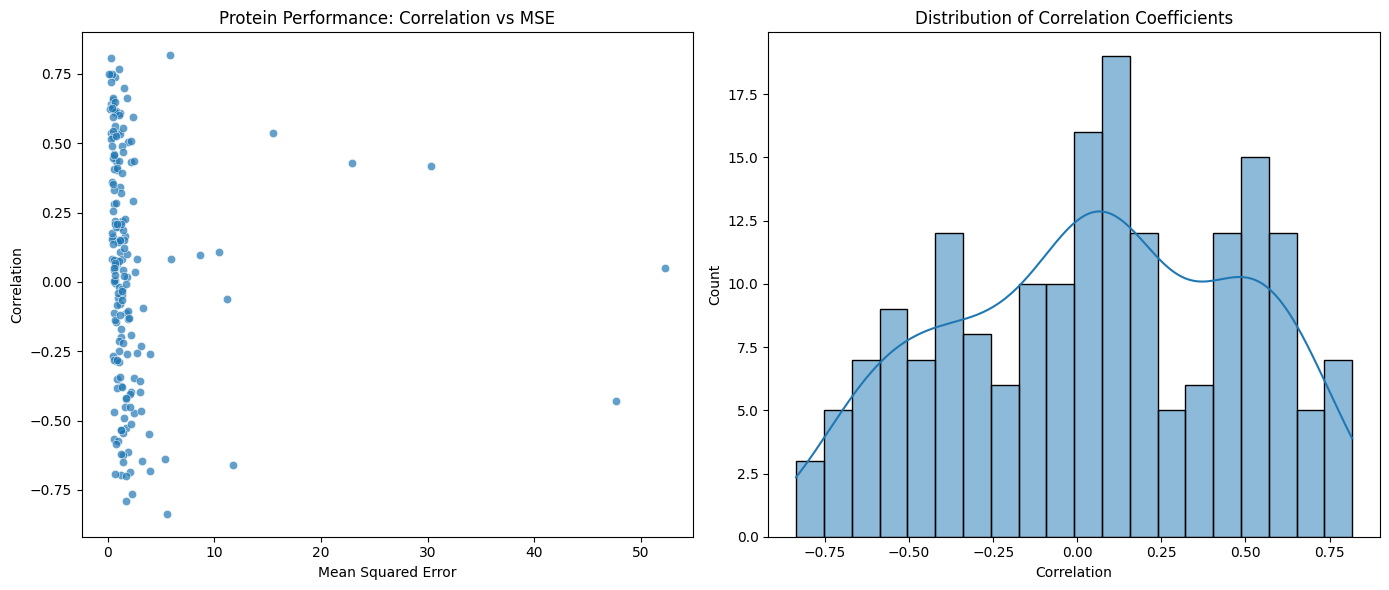

In [19]:

# 10. Global Visualizations

if 'results_df' in locals() and not results_df.empty:
    print("\n--- Global Performance Metrics ---\n")
    
    plt.figure(figsize=(14, 6))
    
    # 1. Correlation vs MSE Scatter
    plt.subplot(1, 2, 1)
    sns.scatterplot(data=results_df, x='MSE', y='Correlation', alpha=0.7)
    plt.title('Protein Performance: Correlation vs MSE')
    plt.xlabel('Mean Squared Error')
    plt.ylabel('Correlation')
    
    # 2. Correlation Distribution
    plt.subplot(1, 2, 2)
    sns.histplot(results_df['Correlation'], bins=20, kde=True)
    plt.title('Distribution of Correlation Coefficients')
    plt.xlabel('Correlation')
    
    plt.tight_layout()
    plt.show()



--- Tissue Performance Comparison ---



C:\Users\hp\AppData\Local\Temp\ipykernel_24060\3732386305.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)


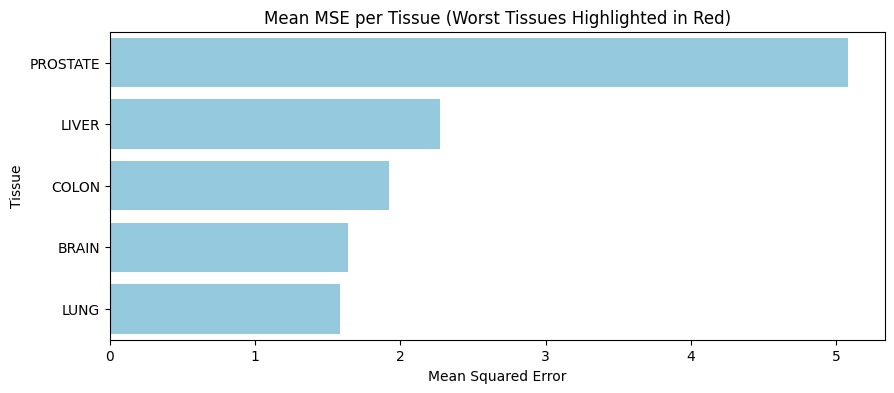

In [20]:

# 11. Tissue Performance Visualization
if 'tissue_df' in locals() and not tissue_df.empty:
    print("\n--- Tissue Performance Comparison ---\n")
    
    # Calculate mean MSE per tissue
    tissue_means = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=False)
    
    plt.figure(figsize=(10, len(tissue_means) * 0.4 + 2))
    
    # Highlight worst tissues
    worst_targets = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
    colors = ['red' if t in worst_targets else 'skyblue' for t in tissue_means.index]
    
    sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)
    plt.title("Mean MSE per Tissue (Worst Tissues Highlighted in Red)")
    plt.xlabel("Mean Squared Error")
    plt.show()
